# Снижение размерности

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

import tensorflow as tf

https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data

Fashion-MNIST — это популярный набор данных для задач компьютерного зрения, который содержит 70 000 grayscale-изображений (в оттенках серого) предметов одежды размером 28×28 пикселей. Он состоит из 60 000 тренировочных и 10 000 тестовых примеров, распределённых по 10 классам.

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

X_train = np.reshape(X_train, (60000,784))
X_test = np.reshape(X_test, (10000, 784))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print("Shape of X_train: ", X_train.shape)
print("Shape of y_train: ", y_train.shape)
print("Shape of X_test: ", X_test.shape)
print("Shape of y_test: ", y_test.shape)

Shape of X_train:  (60000, 784)
Shape of y_train:  (60000,)
Shape of X_test:  (10000, 784)
Shape of y_test:  (10000,)


In [4]:
train_index = range(0,len(X_train))
test_index = range(len(X_train), len(X_train)+len(X_test))

X_train = pd.DataFrame(data=X_train,index=train_index)
y_train = pd.Series(data=y_train,index=train_index)

X_test = pd.DataFrame(data=X_test,index=test_index)
y_test = pd.Series(data=y_test,index=test_index)

In [5]:
labels_dict = {
    0: "tshirt",
    1: "pants",
    2: "sweater",
    3: "dress",
    4: "coat",
    5: "sandal",
    6: "dress_shirt",
    7: "sneaker",
    8: "bag",
    9: "ankleboot",
}

y_train_labels = y_train.map(labels_dict)
y_train_labels.value_counts()

,count
ankleboot,6000
tshirt,6000
dress,6000
sweater,6000
sneaker,6000
sandal,6000
pants,6000
dress_shirt,6000
coat,6000
bag,6000


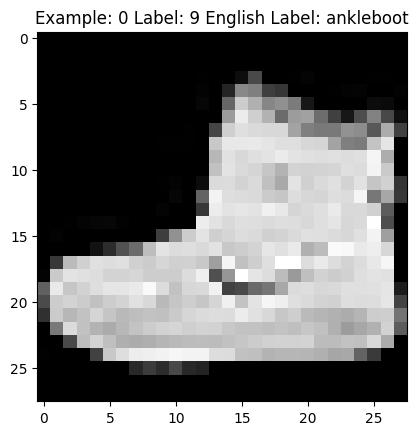

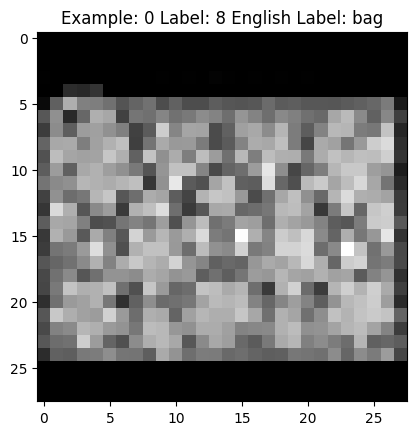

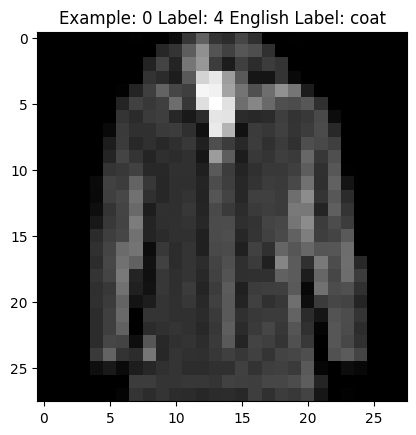

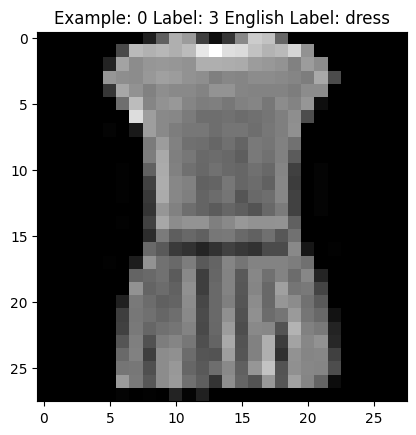

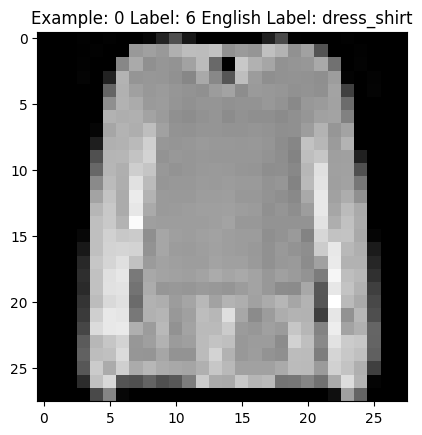

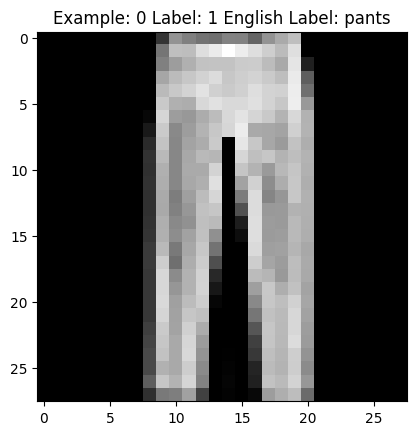

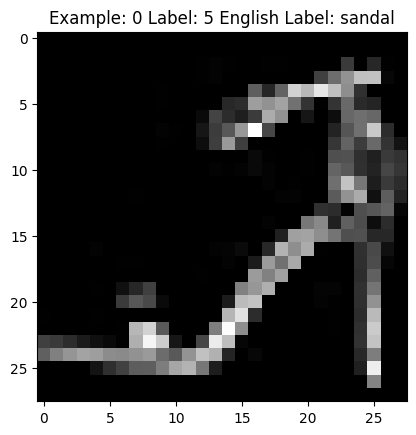

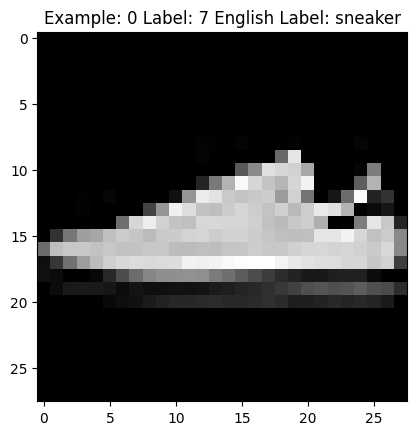

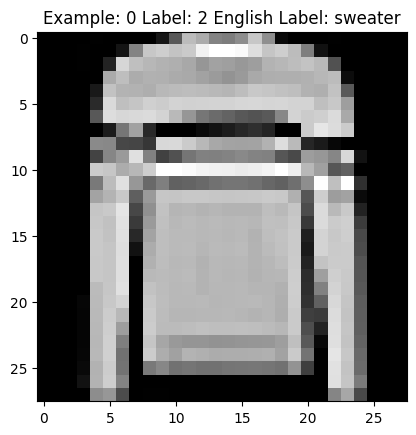

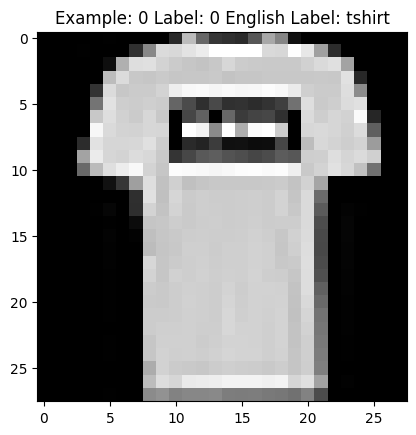

In [6]:
def view_image(data, labels, english_labels, example, type = None):
    if type != None:
      slice = english_labels[english_labels==type].index
      data = data.loc[slice]
    for i in range(example):
      label = labels.loc[slice].iloc[i]
      english_label = english_labels.loc[slice].iloc[i]
      image = data.iloc[i,:].values.reshape([28,28])
      plt.title('Example: %d Label: %d English Label: %s' % (i, label, english_label))
      plt.imshow(image, cmap=plt.get_cmap('gray'))
      plt.show()

for i in np.unique(y_train_labels.values):
  view_image(X_train, y_train, y_train_labels, 1, i)

## PCA

In [7]:
28*28

784

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

pca = PCA(n_components=28*28, random_state=42)

X_train_PCA = pca.fit_transform(X_train)
X_train_PCA = pd.DataFrame(data=X_train_PCA, index=train_index)

print("сохраненено дисперсии:", sum(pca.explained_variance_ratio_))

сохраненено дисперсии: 1.0


In [9]:
pca = PCA(n_components=0.8, random_state=42)

X_train_PCA = pca.fit_transform(X_train)
X_train_PCA = pd.DataFrame(data=X_train_PCA, index=train_index)

print("сохраненено дисперсии:", sum(pca.explained_variance_ratio_))

сохраненено дисперсии: 0.8007059461050499


In [10]:
importanceOfPrincipalComponents = pd.DataFrame(data=pca.explained_variance_ratio_)
importanceOfPrincipalComponents = importanceOfPrincipalComponents.T

<Axes: >

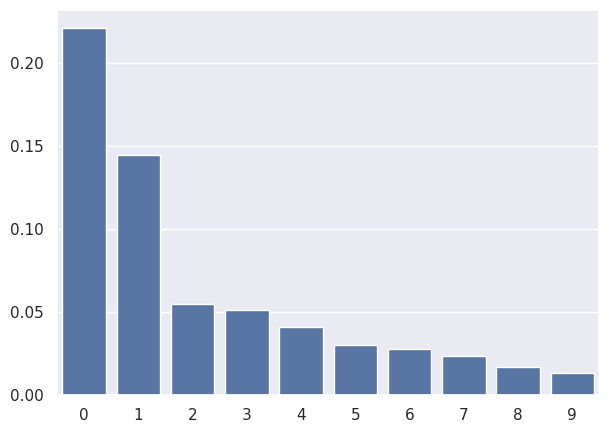

In [11]:
# View percentage captured by first X components
sns.set(rc={'figure.figsize':(7,5)})
sns.barplot(data=importanceOfPrincipalComponents.loc[:,0:9], color='b')

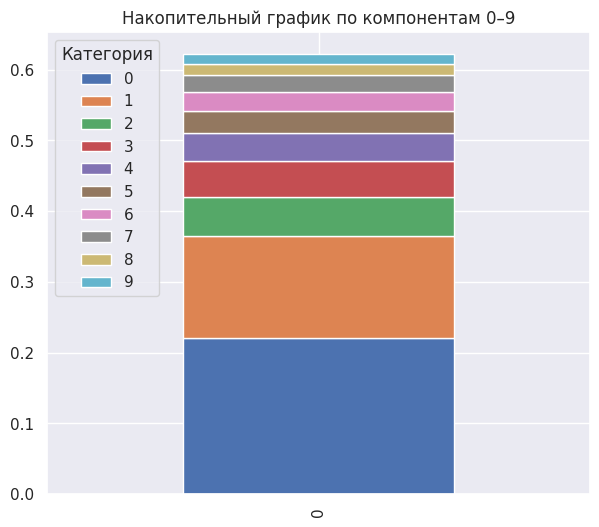

In [12]:
ax = importanceOfPrincipalComponents.loc[:, 0:9].plot(
    kind='bar',
    stacked=True,
    figsize=(7,6))

ax.set_title("Накопительный график по компонентам 0–9")
plt.legend(title="Категория", loc='upper left')
plt.show()

In [13]:
y_train_labels[y_train_labels.iloc[:].isin(['dress'])]

,0
3,dress
20,dress
25,dress
31,dress
47,dress
...,...
59960,dress
59966,dress
59971,dress
59980,dress


In [14]:
y_train_labels[y_train_labels.iloc[:].isin(['dress'])].index

Index([    3,    20,    25,    31,    47,    49,    50,    51,    58,    59,
       ...
       59926, 59928, 59935, 59947, 59954, 59960, 59966, 59971, 59980, 59997],
      dtype='int64', length=6000)

In [15]:
# график по 2 компонентам
def scatterPlot(xDF, yDF, algoName, clothes=labels_dict.values()):
    yDF = yDF[yDF.iloc[:].isin(clothes)]
    tempDF = pd.DataFrame(data=xDF.loc[:,0:1], index=yDF.index)
    tempDF = pd.concat((tempDF,yDF), axis=1, join="inner")
    tempDF.columns = ["x", "y", "Label"]
    sns.lmplot(x="x", y="y", hue="Label", data=tempDF, fit_reg=False,
               scatter_kws={"s": 10}, height=6, aspect=1.4)
    ax = plt.gca()
    ax.set_title("Separation of Observations using "+algoName)

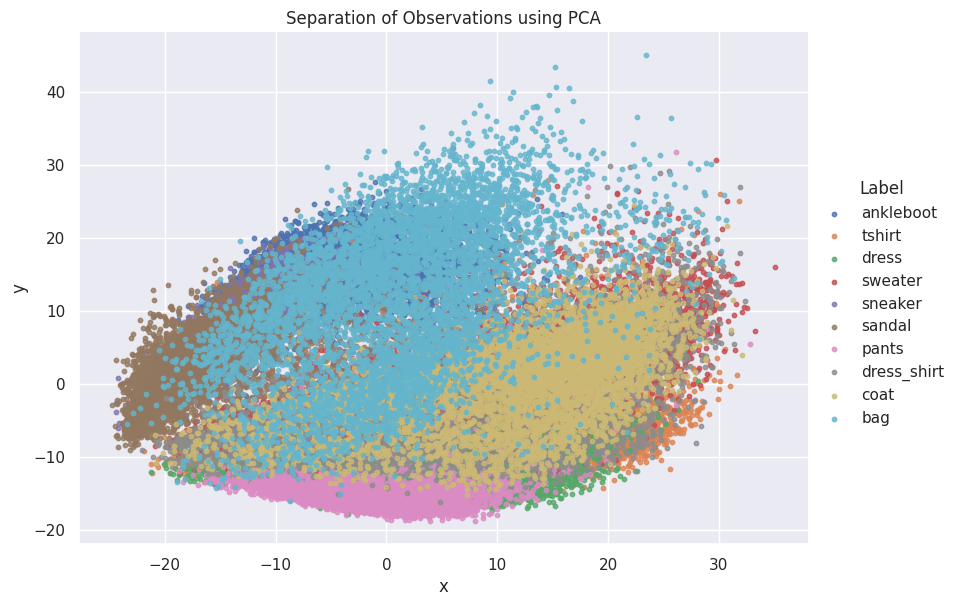

In [16]:
scatterPlot(X_train_PCA, y_train_labels, "PCA")

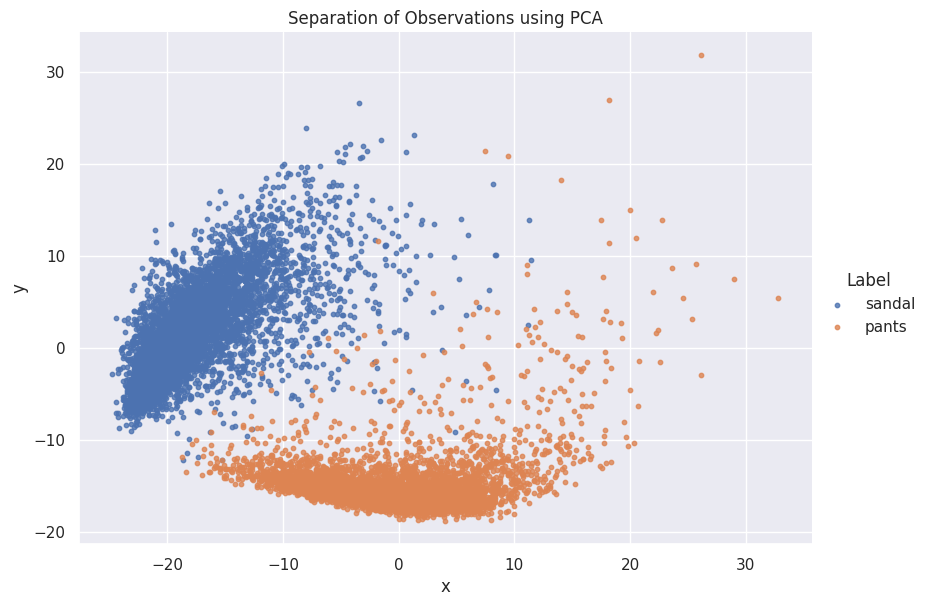

In [17]:
scatterPlot(X_train_PCA, y_train_labels, "PCA", ['pants', 'sandal'])

In [18]:
pca_80 = PCA(n_components=0.8, whiten=True)   #вместо StandardScaler
X_pca_80 = pca_80.fit_transform(X_train)

print("Компонент выбрано:", len(pca_80.explained_variance_ratio_))
print("сохраненено дисперсии:", sum(pca_80.explained_variance_ratio_))

Компонент выбрано: 50
сохраненено дисперсии: 0.8007059461050499


## Incremental PCA

В случае очень больших наборов данных, которые не умещаются в памяти,
можно выполнять анализ инкрементно, работая с небольшими порциями -
пакетами. Размер пакета можно устанавливать вручную или автоматически.
Такой пакетный вариант РСА называется инкрементным.

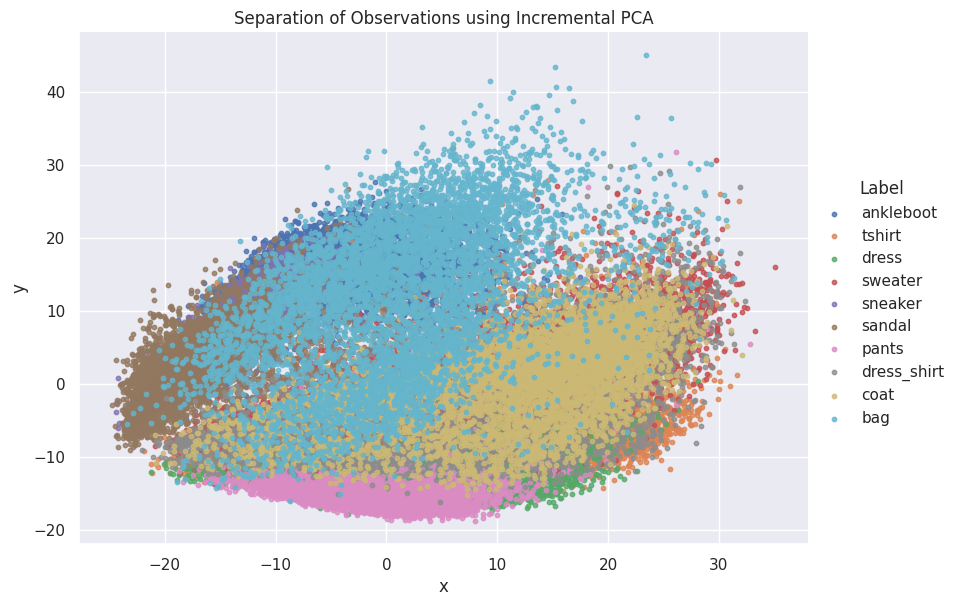

In [19]:
from sklearn.decomposition import IncrementalPCA

n_components = 100
batch_size = None     # 5 * n_features

incrementalPCA = IncrementalPCA(n_components=n_components, batch_size=batch_size)

X_train_incrementalPCA = incrementalPCA.fit_transform(X_train)
X_train_incrementalPCA = pd.DataFrame(data=X_train_incrementalPCA, index=train_index)

scatterPlot(X_train_incrementalPCA, y_train_labels, "Incremental PCA")

## Sparse PCA

У классического PCA есть недостаток: каждая главная компонента обычно является комбинацией всех исходных переменных, что сильно затрудняет их интерпретацию. SPCA решает эту проблему, делая компоненты более понятными: алгоритм явно выделяет ключевые переменные, которые действительно влияют на различия между объектами.

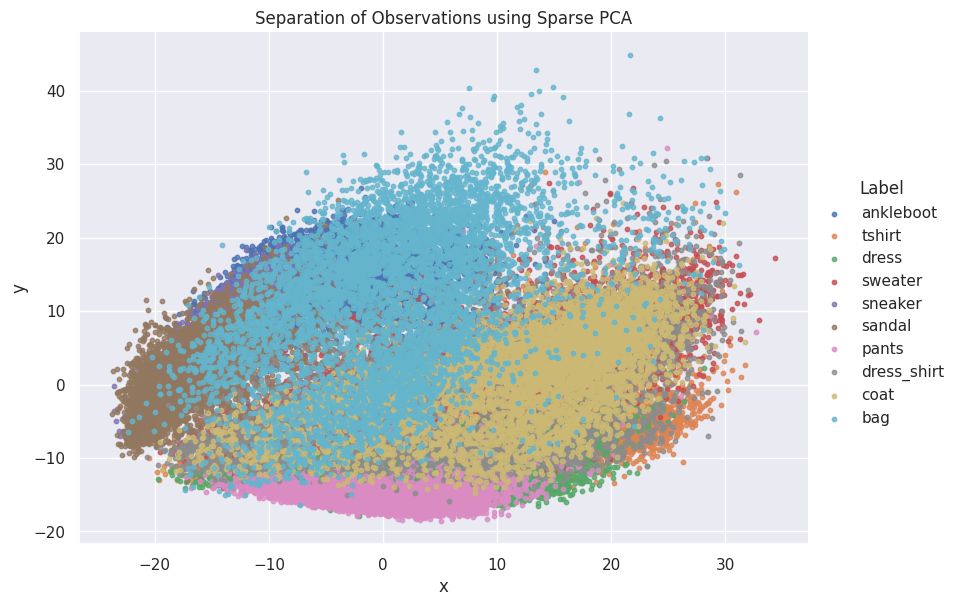

In [20]:
from sklearn.decomposition import SparsePCA

n_components = 100
alpha = 0.0001

# Алгоритм обучается немного медленнее, чем обычный РСА
# будем использовать для тренировки лишь 1000 примеров

sparsePCA = SparsePCA(n_components=n_components, alpha=alpha)

X_train = pd.DataFrame(data=X_train,index=train_index)
sparsePCA.fit(X_train.loc[:1000,:])
X_train_sparsePCA = sparsePCA.transform(X_train)
X_train_sparsePCA = pd.DataFrame(data=X_train_sparsePCA, index=train_index)

scatterPlot(X_train_sparsePCA, y_train_labels, "Sparse PCA")

# Non-Linear Dimensionality Reduction

## Kernel PCA

Нелинейное обобщение обычного метода главных компонент.
Умеет выделять нелинейные структуры, где обычный PCA плохо работает.


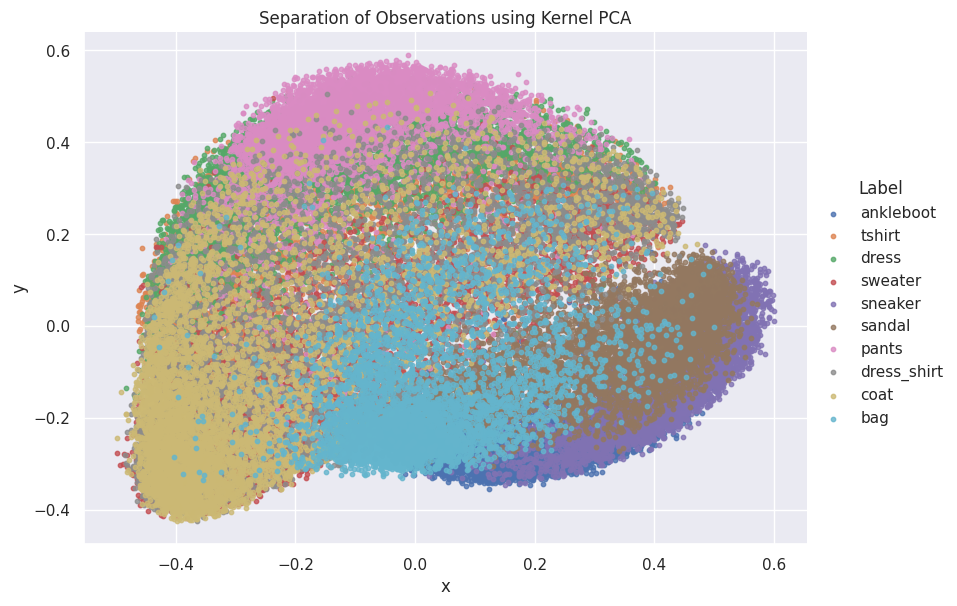

In [21]:
from sklearn.decomposition import KernelPCA

n_components = 100
kernel = 'rbf'    # радиально-базисная функция
                  # 'rbf', 'poly', 'sigmoid', 'cosine', 'precomputed'
gamma = None      # ширина RBF-ядра

kernelPCA = KernelPCA(n_components=n_components, kernel=kernel, gamma=gamma)

kernelPCA.fit(X_train.loc[:1000,:])
X_train_kernelPCA = kernelPCA.transform(X_train)
X_train_kernelPCA = pd.DataFrame(data=X_train_kernelPCA,index=train_index)

scatterPlot(X_train_kernelPCA, y_train_labels, "Kernel PCA")

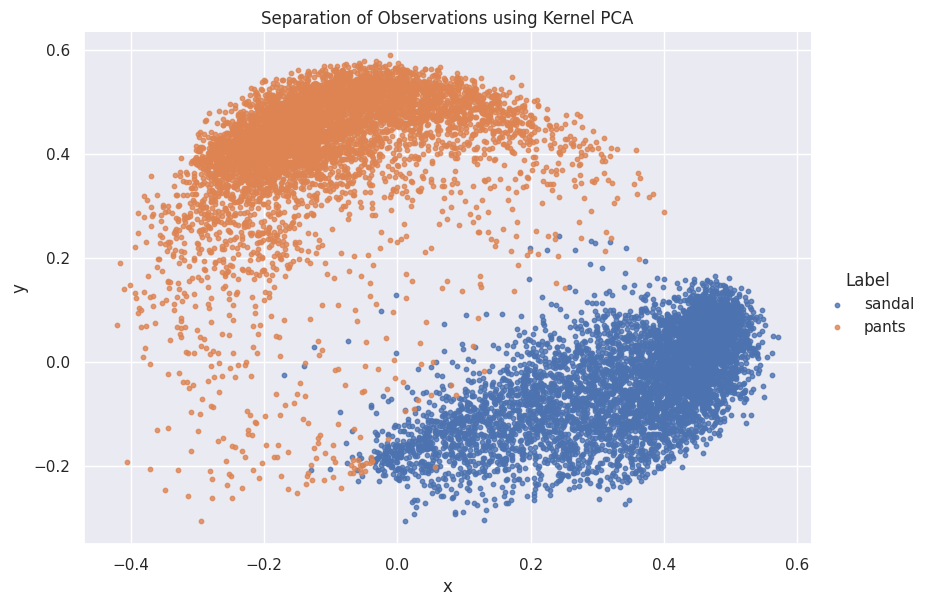

In [22]:
scatterPlot(X_train_kernelPCA, y_train_labels, "Kernel PCA", ['sandal', 'pants'])

## Isomap

In [23]:
# # это ускоряет поиск соседей и убирает выбросы

# pca = PCA(n_components=0.9, random_state=42)

# X_train_PCA = pca.fit_transform(X_train)
# X_train_PCA = pd.DataFrame(data=X_train_PCA, index=train_index)

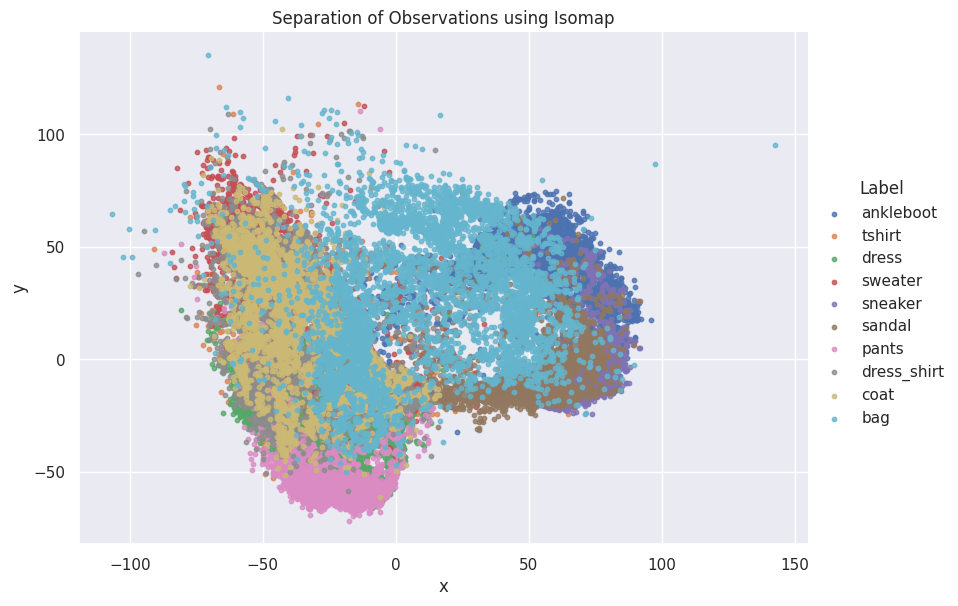

In [24]:
from sklearn.manifold import Isomap

n_neighbors = 5
n_components = 10

isomap = Isomap(n_neighbors=n_neighbors, n_components=n_components)

isomap.fit(X_train_PCA.loc[0:1000,:])
X_train_isomap = isomap.transform(X_train_PCA)
X_train_isomap = pd.DataFrame(data=X_train_isomap, index=train_index)

scatterPlot(X_train_isomap, y_train_labels, "Isomap")

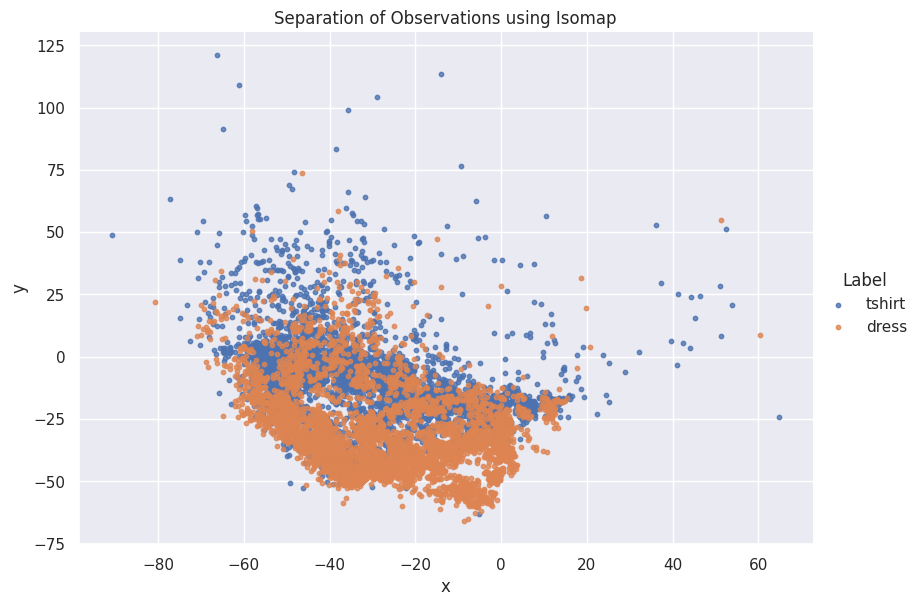

In [25]:
scatterPlot(X_train_isomap, y_train_labels, "Isomap", ['tshirt', 'dress'])

## t-SNE

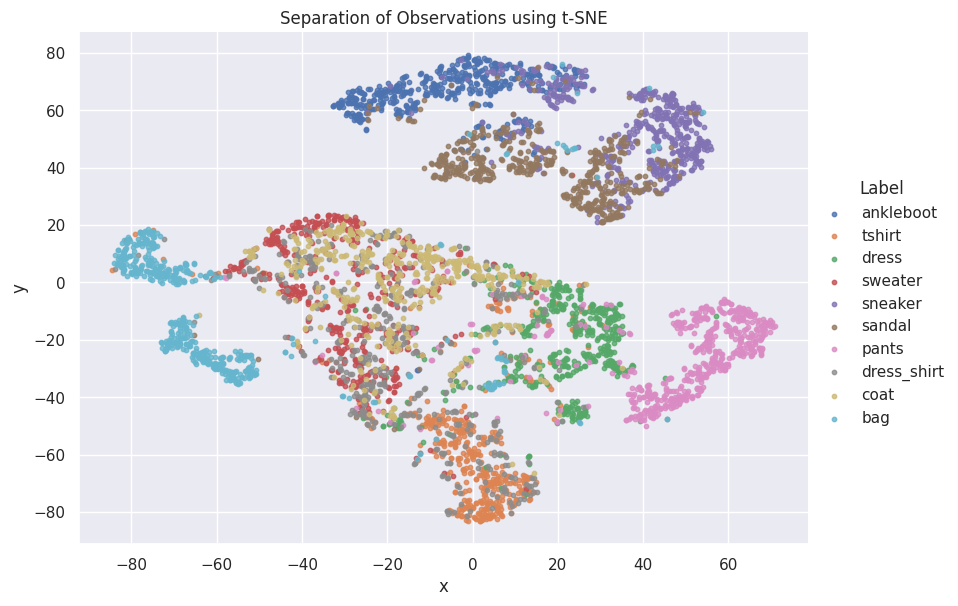

In [26]:
from sklearn.manifold import TSNE

n_components = 2
learning_rate = 300
perplexity = 30
early_exaggeration = 12

tSNE = TSNE(n_components=n_components, learning_rate=learning_rate,
            perplexity=perplexity, early_exaggeration=early_exaggeration, init='random')

X_train_tSNE = tSNE.fit_transform(X_train_PCA.loc[:5000,:9])
X_train_tSNE = pd.DataFrame(data=X_train_tSNE, index=train_index[:5001])

scatterPlot(X_train_tSNE, y_train_labels, "t-SNE")